In [4]:
# Sincronización de imágenes desde S3

# Descargamos las imágenes al disco local del notebook. Usamos "sync" para que
# las imágenes originales en el bucket nunca se toquen, solo se copian.

import os
import subprocess

LOCAL_DATA_DIR = "data"
os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_detection"

# --quiet evita imprimir una línea por cada archivo copiado
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/damaged/", f"{LOCAL_DATA_DIR}/damaged/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/undamaged/", f"{LOCAL_DATA_DIR}/undamaged/", "--quiet"], check=True)

# Conteo de imágenes por clase
n_damaged = len(os.listdir(f"{LOCAL_DATA_DIR}/damaged"))
n_undamaged = len(os.listdir(f"{LOCAL_DATA_DIR}/undamaged"))
print(f"Dañadas: {n_damaged} | No dañadas: {n_undamaged}")

Dañadas: 11194 | No dañadas: 12981


In [5]:
# Creación de los datasets de entrenamiento, validación y test.

# El 30% de validation_split se reparte a la mitad entre val y test.
# class_names se guarda antes del prefetch porque luego de esa transformación
# el objeto pierde ese atributo.
#
# BATCH_SIZE: originalmente 32, se bajó a 16 porque con 32 la instancia
# se quedaba sin memoria RAM durante el entrenamiento
#
# Sin .cache(): originalmente se usaba .cache() para acelerar épocas siguientes,
# pero cachear el dataset completo en RAM también contribuía al problema de
# memoria. Se sacó a cambio de un poco más de lentitud por época.

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DATA_DIR,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DATA_DIR,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_batches = tf.data.experimental.cardinality(val_test_ds)
val_ds = val_test_ds.take(val_batches // 2)
test_ds = val_test_ds.skip(val_batches // 2)

class_names = train_ds.class_names
print("Clases:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 24174 files belonging to 2 classes.
Using 16922 files for training.
Found 24174 files belonging to 2 classes.
Using 7252 files for validation.
Clases: ['damaged', 'undamaged']


In [3]:
# Data augmentation: aplica variaciones aleatorias a las imágenes durante el
# entrenamiento (flip, rotación, zoom, contraste) para que el modelo generalice
# mejor y no memorice las imágenes de train. Se aplica solo durante el
# entrenamiento, no en validación/test ni en predicciones nuevas.
# El zoom ayuda especialmente porque el dataset tiene fotos de cerca y de lejos.

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.15),
])

In [ ]:
# IMPORTANTE: esta celda solo se corre para crear el modelo desde cero.
# Si ya existe un "best_model.keras" entrenado y se quiere continuar el
# entrenamiento o solo evaluar/predecir, NO correr esta celda —
# usar tf.keras.models.load_model("best_model.keras")
#
# Arquitectura de la CNN, entrenada desde cero (sin transfer learning).
# 4 bloques convolucionales (32 -> 64 -> 128 -> 256 filtros), cada uno con
# BatchNormalization y MaxPooling. Termina en GlobalAveragePooling + Dense
# + Dropout, con salida sigmoid para clasificación binaria.

from tensorflow.keras import layers, models

def build_cnn(input_shape=(224, 224, 3)):
    inputs = tf.keras.Input(shape=input_shape)

    x = layers.Rescaling(1./255)(inputs)
    x = data_augmentation(x)

    # Bloque 1
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Bloque 2
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Bloque 3
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Bloque 4
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    return models.Model(inputs, outputs)

model = build_cnn()
model.summary()

In [ ]:
# Carga el modelo entrenado desde el checkpoint guardado en disco.
# Esta es la celda que se usa normalmente para continuar entrenando,
# evaluar, o hacer predicciones sobre imágenes nuevas — en vez de
# correr build_cnn() y perder el progreso ya entrenado.

import tensorflow as tf

model = tf.keras.models.load_model("../models/best_model.keras")
print("Modelo cargado correctamente")
model.summary()

2026-08-01 18:20:17.088047: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2026-08-01 18:20:17.088088: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:178] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2026-08-01 18:20:17.088095: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] retrieving CUDA diagnostic information for host: default
2026-08-01 18:20:17.088099: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:190] hostname: default
2026-08-01 18:20:17.088261: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:197] libcuda reported version is: 595.71.5
2026-08-01 18:20:17.088282: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:201] kernel reported versi

Modelo cargado correctamente


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,268,165 (4.84 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 844,804 (3.22 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    tf.keras.callbacks.ModelCheckpoint("../models/best_model.keras", monitor="val_recall", mode="max", save_best_only=True)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50
496/529 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.8593 - loss: 0.3398 - precision: 0.8657 - recall: 0.8694

Invalid SOS parameters for sequential JPEG


529/529 ━━━━━━━━━━━━━━━━━━━━ 932s 2s/step - accuracy: 0.8802 - loss: 0.2998 - precision: 0.8813 - recall: 0.8967 - val_accuracy: 0.8078 - val_loss: 0.4316 - val_precision: 0.9640 - val_recall: 0.6704 - learning_rate: 0.0010
Epoch 2/50
529/529 ━━━━━━━━━━━━━━━━━━━━ 859s 2s/step - accuracy: 0.9094 - loss: 0.2348 - precision: 0.9100 - recall: 0.9218 - val_accuracy: 0.8977 - val_loss: 0.2619 - val_precision: 0.8565 - val_recall: 0.9745 - learning_rate: 0.0010
Epoch 3/50
529/529 ━━━━━━━━━━━━━━━━━━━━ 859s 2s/step - accuracy: 0.9190 - loss: 0.2105 - precision: 0.9225 - recall: 0.9265 - val_accuracy: 0.8778 - val_loss: 0.3535 - val_precision: 0.8280 - val_recall: 0.9776 - learning_rate: 0.0010
Epoch 4/50
529/529 ━━━━━━━━━━━━━━━━━━━━ 856s 2s/step - accuracy: 0.9236 - loss: 0.1993 - precision: 0.9277 - recall: 0.9297 - val_accuracy: 0.8861 - val_loss: 0.2689 - val_precision: 0.9674 - val_recall: 0.8173 - learning_rate: 0.0010
Epoch 5/50
529/529 ━━━━━━━━━━━━━━━━━━━━ 855s 2s/step - accuracy: 0.9281

In [ ]:
# Primera versión del entrenamiento: compila el modelo y entrena de una sola
# tanda hasta 50 épocas (con EarlyStopping para cortar antes si no mejora).
#
# NOTA: esta versión se interrumpió varias veces durante el entrenamiento real
# (kernel murió por falta de memoria, y el espacio se apagó por inactividad).
# El entrenamiento efectivo se completó con el enfoque de tandas cortas
# (ver celda "MemoryCleanup" + fit en bloques de 5 épocas, más abajo),
# que permite retomar desde el último checkpoint si algo falla.
# Esta celda queda solo como referencia de cómo se compiló el modelo
# la primera vez — no hace falta volver a correrla si ya existe
# un best_model.keras entrenado.

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    tf.keras.callbacks.ModelCheckpoint("../models/best_model.keras", monitor="val_recall", mode="max", save_best_only=True)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/30
1009/1058 ━━━━━━━━━━━━━━━━━━━━ 38s 785ms/step - accuracy: 0.9536 - loss: 0.1237 - precision: 0.9607 - recall: 0.9522

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 872s 821ms/step - accuracy: 0.9532 - loss: 0.1235 - precision: 0.9612 - recall: 0.9508 - val_accuracy: 0.9345 - val_loss: 0.1572 - val_precision: 0.9491 - val_recall: 0.9288 - learning_rate: 2.5000e-04
Epoch 2/30
1005/1058 ━━━━━━━━━━━━━━━━━━━━ 41s 791ms/step - accuracy: 0.9523 - loss: 0.1200 - precision: 0.9602 - recall: 0.9499

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 876s 827ms/step - accuracy: 0.9552 - loss: 0.1175 - precision: 0.9625 - recall: 0.9534 - val_accuracy: 0.9185 - val_loss: 0.2114 - val_precision: 0.9026 - val_recall: 0.9515 - learning_rate: 2.5000e-04
Epoch 3/30
1002/1058 ━━━━━━━━━━━━━━━━━━━━ 44s 793ms/step - accuracy: 0.9603 - loss: 0.1056 - precision: 0.9655 - recall: 0.9600

Invalid SOS parameters for sequential JPEG


... (13 outputs left out)

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 876s 828ms/step - accuracy: 0.9630 - loss: 0.0970 - precision: 0.9690 - recall: 0.9616 - val_accuracy: 0.7740 - val_loss: 0.8718 - val_precision: 0.7193 - val_recall: 0.9531 - learning_rate: 1.2500e-04
Epoch 11/30
1009/1058 ━━━━━━━━━━━━━━━━━━━━ 38s 795ms/step - accuracy: 0.9634 - loss: 0.0947 - precision: 0.9708 - recall: 0.9605

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 880s 831ms/step - accuracy: 0.9627 - loss: 0.0978 - precision: 0.9691 - recall: 0.9609 - val_accuracy: 0.9353 - val_loss: 0.1681 - val_precision: 0.9185 - val_recall: 0.9658 - learning_rate: 1.2500e-04


In [ ]:
# Callbacks para el entrenamiento en tandas cortas.
# Se agrega MemoryCleanup (fuerza garbage collection al final de cada época)
# como intento de mitigar la acumulación de memoria que causaba que el
# kernel muriera durante entrenamientos largos y continuos.
#
# Nota: EarlyStopping no tiene memoria entre tandas separadas de fit() —
# cada vez que se corre una tanda nueva, el patience se reinicia. El criterio
# de cuándo parar de entrenar queda en observar manualmente si val_loss
# sigue mejorando entre tandas.

import gc
from tensorflow.keras.callbacks import Callback

class MemoryCleanup(Callback):
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    tf.keras.callbacks.ModelCheckpoint("../models/best_model.keras", monitor="val_recall", mode="max", save_best_only=True),
    MemoryCleanup()
]

In [ ]:
# Entrenamiento en tandas cortas de 5 épocas.
# Carga el mejor checkpoint guardado y entrena 5 épocas más sobre él.
#
# Entrenamiento final: se corrió hasta que val_loss dejó de mejorar de forma
# consistente entre tandas (modelo llegó a una meseta).

model = tf.keras.models.load_model("../models/best_model.keras")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
1009/1058 ━━━━━━━━━━━━━━━━━━━━ 38s 794ms/step - accuracy: 0.9600 - loss: 0.1041 - precision: 0.9666 - recall: 0.9583

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 882s 830ms/step - accuracy: 0.9583 - loss: 0.1082 - precision: 0.9653 - recall: 0.9565 - val_accuracy: 0.8422 - val_loss: 0.3404 - val_precision: 0.8429 - val_recall: 0.8708 - learning_rate: 2.5000e-04
Epoch 2/5
1004/1058 ━━━━━━━━━━━━━━━━━━━━ 43s 806ms/step - accuracy: 0.9619 - loss: 0.1030 - precision: 0.9689 - recall: 0.9594

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 892s 842ms/step - accuracy: 0.9612 - loss: 0.1043 - precision: 0.9687 - recall: 0.9585 - val_accuracy: 0.9444 - val_loss: 0.1516 - val_precision: 0.9266 - val_recall: 0.9740 - learning_rate: 2.5000e-04
Epoch 3/5
1001/1058 ━━━━━━━━━━━━━━━━━━━━ 45s 798ms/step - accuracy: 0.9603 - loss: 0.1031 - precision: 0.9680 - recall: 0.9574

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 882s 833ms/step - accuracy: 0.9598 - loss: 0.1060 - precision: 0.9672 - recall: 0.9572 - val_accuracy: 0.9452 - val_loss: 0.1410 - val_precision: 0.9505 - val_recall: 0.9481 - learning_rate: 2.5000e-04
Epoch 4/5
1002/1058 ━━━━━━━━━━━━━━━━━━━━ 44s 797ms/step - accuracy: 0.9627 - loss: 0.0959 - precision: 0.9698 - recall: 0.9600

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 882s 833ms/step - accuracy: 0.9601 - loss: 0.1025 - precision: 0.9672 - recall: 0.9579 - val_accuracy: 0.9339 - val_loss: 0.2050 - val_precision: 0.9143 - val_recall: 0.9684 - learning_rate: 2.5000e-04
Epoch 5/5
1007/1058 ━━━━━━━━━━━━━━━━━━━━ 40s 793ms/step - accuracy: 0.9627 - loss: 0.1002 - precision: 0.9726 - recall: 0.9570

Invalid SOS parameters for sequential JPEG


1058/1058 ━━━━━━━━━━━━━━━━━━━━ 878s 830ms/step - accuracy: 0.9622 - loss: 0.1026 - precision: 0.9704 - recall: 0.9586 - val_accuracy: 0.9331 - val_loss: 0.1807 - val_precision: 0.9129 - val_recall: 0.9684 - learning_rate: 2.5000e-04


Invalid SOS parameters for sequential JPEG
2026-08-01 18:31:19.200559: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


              precision    recall  f1-score   support

     damaged       0.97      0.90      0.94      1657
   undamaged       0.92      0.98      0.95      1963

    accuracy                           0.94      3620
   macro avg       0.95      0.94      0.94      3620
weighted avg       0.95      0.94      0.94      3620



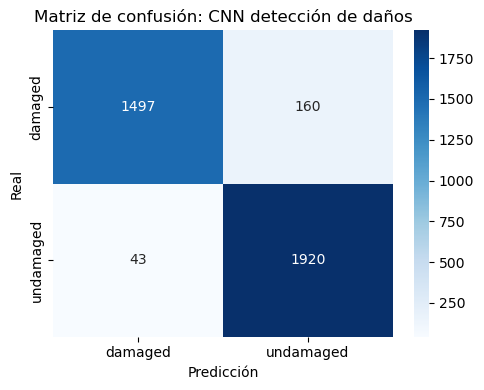

ROC-AUC: 0.9907

Precision: de todo lo que el modelo predijo como una clase, qué porcentaje
           realmente era esa clase (mide falsas alarmas).
Recall:    de todo lo que realmente era esa clase, qué porcentaje el modelo
           detectó correctamente (mide casos no detectados / falsos negativos).
           Es la métrica más importante acá: un recall bajo en 'damaged'
           significa dejar pasar daños estructurales reales.
F1-score:  balance entre precision y recall en un solo número.
ROC-AUC:   qué tan bien separa el modelo ambas clases en general, probando
           todos los umbrales de decisión posibles (no solo 0.5).
           1.0 = separación perfecta | 0.5 = equivalente a azar.



In [ ]:
# Evaluación final del modelo sobre el set de test (imágenes nunca vistas).
#
# Requiere haber corrido antes: la celda de sincronización con S3, y la celda
# que crea train_ds/val_ds/test_ds/class_names. No hace falta correr las
# celdas de data augmentation ni de arquitectura del modelo para evaluar.
#
# Por qué depende de esa celda: test_ds se calcula a partir del mismo split
# que train_ds (mismo seed, mismo validation_split), para garantizar que el
# test sea consistente y no se mezcle con lo que el modelo vio en entrenamiento.
# Como train_ds y test_ds se generan juntos en una sola celda, no se puede
# crear test_ds por separado sin correr esa celda completa (aunque no se use
# train_ds acá para evaluar).
#
# Nota técnica importante: y_true e y_pred_prob se arman en el MISMO loop,
# batch por batch, para evitar que el orden de las imágenes se desalinee
# entre etiquetas reales y predicciones (esto pasó en un intento anterior
# y generó métricas completamente erróneas, tipo ROC-AUC ~0.5).

import tensorflow as tf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = tf.keras.models.load_model("../models/best_model.keras")

y_true = []
y_pred_prob = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.append(labels.numpy())
    y_pred_prob.append(preds)

y_true = np.concatenate(y_true)
y_pred_prob = np.concatenate(y_pred_prob)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de confusión: CNN detección de daños")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

roc_auc = roc_auc_score(y_true, y_pred_prob)
print(f"ROC-AUC: {roc_auc:.4f}")

print("""
Precision: de todo lo que el modelo predijo como una clase, qué porcentaje
           realmente era esa clase (mide falsas alarmas).
Recall:    de todo lo que realmente era esa clase, qué porcentaje el modelo
           detectó correctamente (mide casos no detectados / falsos negativos).
           Es la métrica más importante acá: un recall bajo en 'damaged'
           significa dejar pasar daños estructurales reales.
F1-score:  balance entre precision y recall en un solo número.
ROC-AUC:   qué tan bien separa el modelo ambas clases en general, probando
           todos los umbrales de decisión posibles (no solo 0.5).
           1.0 = separación perfecta | 0.5 = equivalente a azar.
""")

Se encontraron 5 imágenes en 'prueba'



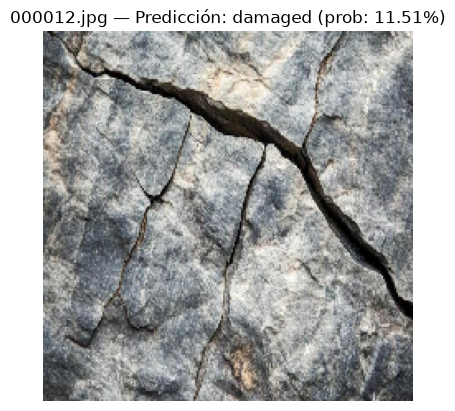

000012.jpg: damaged (probabilidad cruda hacia 'undamaged': 0.1151)



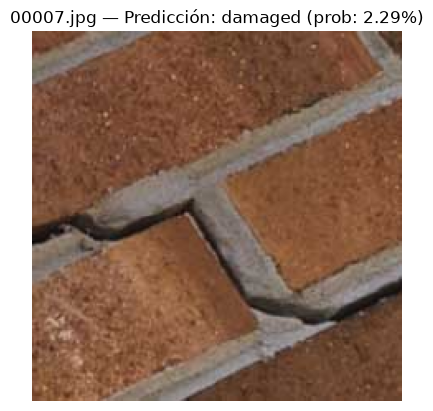

00007.jpg: damaged (probabilidad cruda hacia 'undamaged': 0.0229)



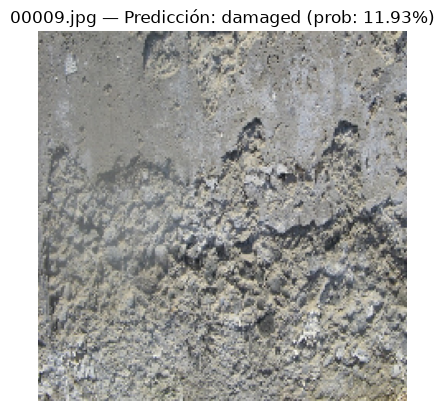

00009.jpg: damaged (probabilidad cruda hacia 'undamaged': 0.1193)



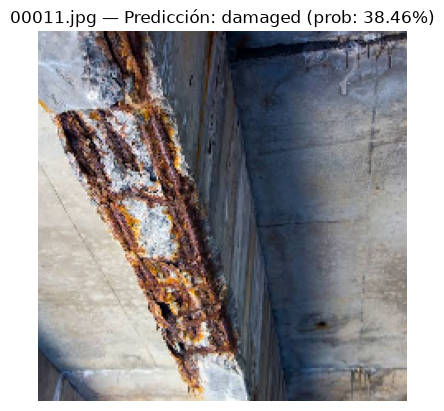

00011.jpg: damaged (probabilidad cruda hacia 'undamaged': 0.3846)



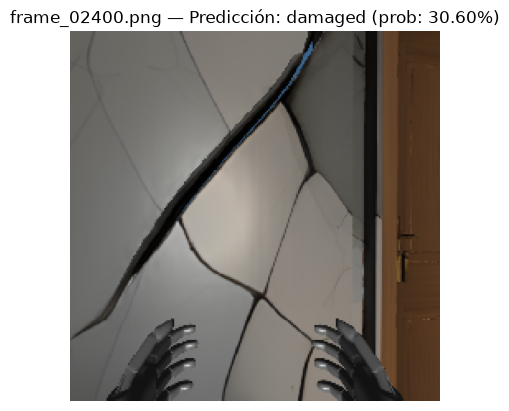

frame_02400.png: damaged (probabilidad cruda hacia 'undamaged': 0.3060)



In [1]:
# Predicción sobre imágenes nuevas.
# Recorre todas las imágenes dentro de la carpeta indicada y muestra
# la predicción del modelo para cada una.

import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("../models/modelo_detection.keras")

FOLDER_PATH = "prueba"

# Extensiones de imagen válidas
valid_extensions = (".jpg", ".jpeg", ".png")
image_files = [f for f in os.listdir(FOLDER_PATH) if f.lower().endswith(valid_extensions)]

print(f"Se encontraron {len(image_files)} imágenes en '{FOLDER_PATH}'\n")

for filename in image_files:
    image_path = os.path.join(FOLDER_PATH, filename)

    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    pred_prob = model.predict(img_array, verbose=0)[0][0]
    pred_label = "damaged" if pred_prob < 0.5 else "undamaged"

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{filename} — Predicción: {pred_label} (prob: {pred_prob:.2%})")
    plt.show()

    print(f"{filename}: {pred_label} (probabilidad cruda hacia 'undamaged': {pred_prob:.4f})\n")